# 🌊 Harbour Watch — Data Report
_Everything below is computed from the cleaned warehouse (`output/warehouse.duckdb`), not the raw files — the sample covers 3 stations across 2025._

In [1]:
import duckdb, pandas as pd, numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from pathlib import Path

# One consistent palette for object classes, reused in EVERY chart.
CLASS_COLORS = {'boat':'#2563eb','vehicle':'#f59e0b','person':'#10b981','bird':'#8b5cf6','drone':'#ef4444'}
INK='#1f2937'; MUTE='#6b7280'; GRID='#e5e7eb'
plt.rcParams.update({
  'figure.facecolor':'white','axes.facecolor':'white','savefig.facecolor':'white',
  'figure.dpi':120,'font.size':10.5,'font.family':'DejaVu Sans',
  'axes.titlesize':13,'axes.titleweight':'bold','axes.titlepad':12,'axes.titlecolor':INK,
  'axes.labelsize':10.5,'axes.labelcolor':MUTE,'axes.edgecolor':GRID,'axes.linewidth':1.2,
  'axes.grid':True,'grid.color':GRID,'grid.linewidth':0.9,'grid.alpha':0.7,
  'axes.spines.top':False,'axes.spines.right':False,
  'xtick.color':MUTE,'ytick.color':MUTE,'text.color':INK,'legend.frameon':False,'legend.fontsize':9,
})
def cols(classes): return [CLASS_COLORS.get(c,'#9ca3af') for c in classes]
def despine(ax):
    ax.tick_params(length=0)
    for s in ax.spines.values(): s.set_visible(False)
    ax.grid(axis='x', alpha=0.6); ax.set_axisbelow(True)

db = next(p for p in [Path('../output/warehouse.duckdb'), Path('output/warehouse.duckdb')] if p.exists())
con = duckdb.connect(str(db), read_only=True)
q = lambda s: con.execute(s).df()
print('warehouse:', db.resolve())

warehouse: /home/jorge/git/Data-Engineering-Prueba/output/warehouse.duckdb


## 1 · What does the data look like?
How many objects of each class, and how balanced the classes are per station and over time.

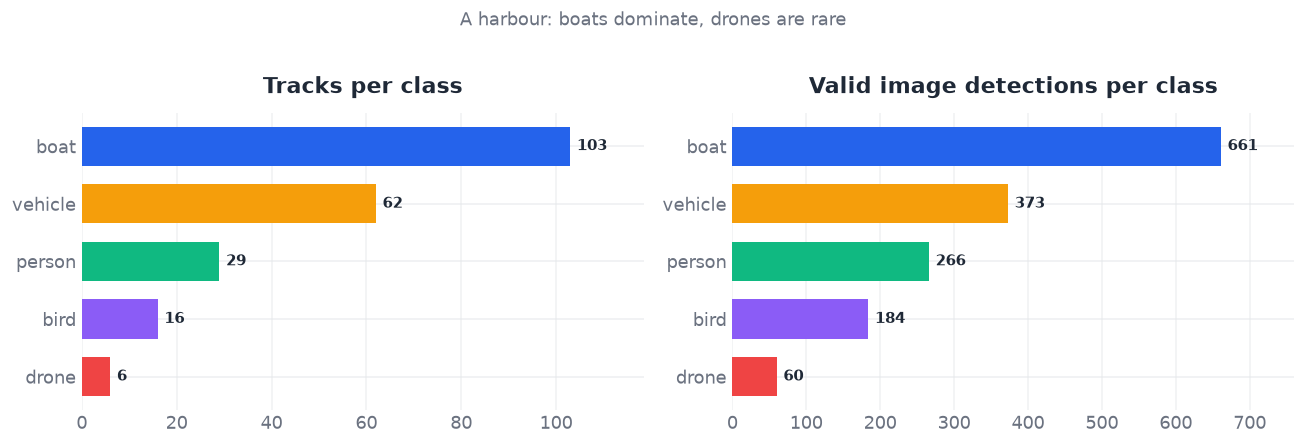

In [2]:
tpc = q("SELECT class, COUNT(*) n FROM (SELECT station_id,track_id,MIN(class) class "
        "FROM track_points GROUP BY 1,2) GROUP BY 1 ORDER BY n")
dpc = q("SELECT class, COUNT(*) n FROM image_detections WHERE is_valid GROUP BY 1 ORDER BY n")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for a, d, title in [(ax[0], tpc, 'Tracks per class'), (ax[1], dpc, 'Valid image detections per class')]:
    bars = a.barh(d['class'], d['n'], color=cols(d['class']), height=0.68, zorder=3)
    a.bar_label(bars, padding=4, color=INK, fontsize=9, fontweight='bold')
    a.set_title(title); a.margins(x=0.15); despine(a)
fig.suptitle('A harbour: boats dominate, drones are rare', fontsize=11, color=MUTE, y=1.02)
plt.tight_layout(); plt.show()

/tmp/ipykernel_3920313/614379046.py:4: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  share = piv.div(piv.sum(1), axis=0)[list(CLASS_COLORS)]


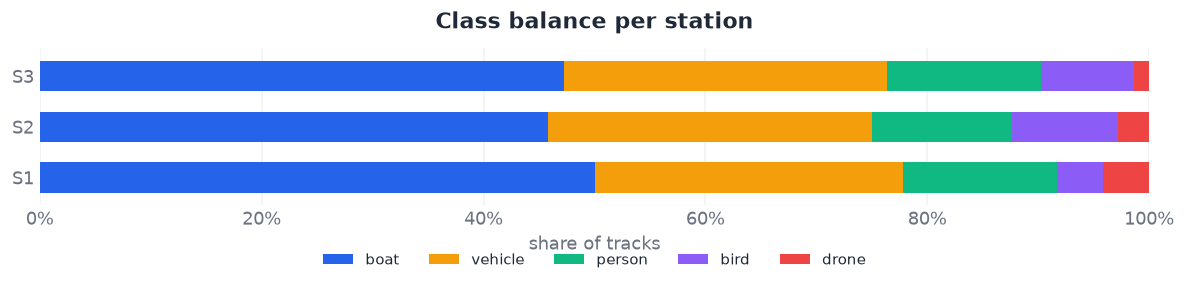

In [3]:
bs = q("SELECT station_id, class, COUNT(*) n FROM (SELECT station_id,track_id,MIN(class) class "
       "FROM track_points GROUP BY 1,2) GROUP BY 1,2")
piv = bs.pivot(index='station_id', columns='class', values='n').fillna(0)
share = piv.div(piv.sum(1), axis=0)[list(CLASS_COLORS)]
ax = share.plot(kind='barh', stacked=True, color=list(CLASS_COLORS.values()),
                figsize=(10, 2.8), width=0.6, zorder=3)
ax.set_title('Class balance per station'); ax.set_xlabel('share of tracks'); ax.set_ylabel('')
ax.xaxis.set_major_formatter(PercentFormatter(1.0)); ax.margins(x=0)
ax.legend(ncol=5, bbox_to_anchor=(0.5, -0.35), loc='center'); despine(ax)
plt.tight_layout(); plt.show()

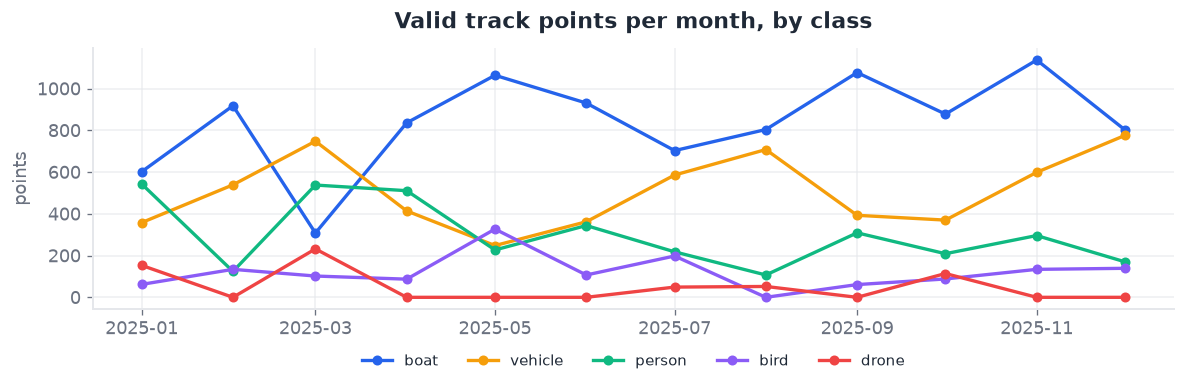

In [4]:
ot = q("SELECT date_trunc('month', ts_utc) m, class, COUNT(*) n FROM track_points GROUP BY 1,2 ORDER BY 1")
otp = ot.pivot(index='m', columns='class', values='n').fillna(0)[list(CLASS_COLORS)]
fig, a = plt.subplots(figsize=(10, 3.4))
for c in otp.columns:
    a.plot(otp.index, otp[c], marker='o', ms=5, lw=2, color=CLASS_COLORS[c], label=c, zorder=3)
a.set_title('Valid track points per month, by class'); a.set_ylabel('points')
a.legend(ncol=5, loc='upper center', bbox_to_anchor=(0.5, -0.12))
for s in ['top','right']: a.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

**Cross-source check — do the tracker and the cameras agree?**  
The class mix seen by two *independent* sensors is a sanity check on the data.

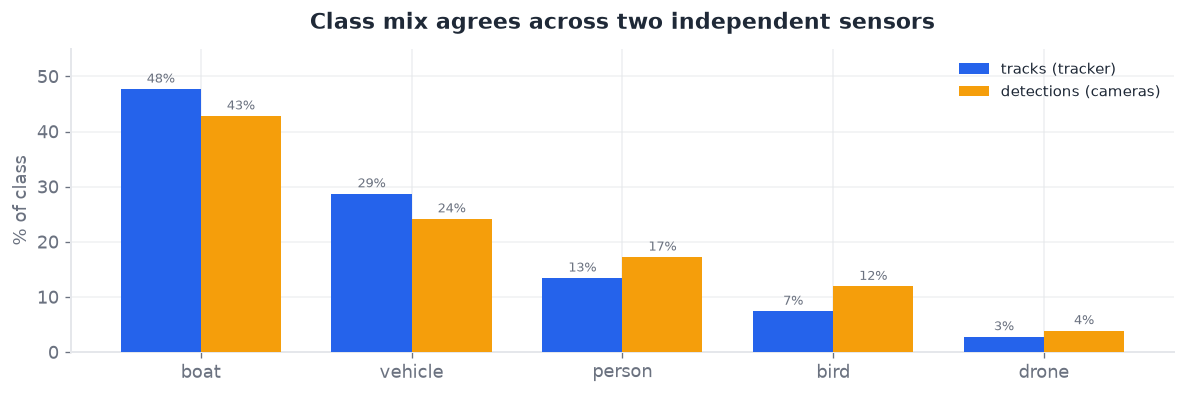

In [5]:
cmp = q("WITH t AS (SELECT class, COUNT(*) n FROM (SELECT station_id,track_id,MIN(class) class FROM track_points GROUP BY 1,2) GROUP BY 1), d AS (SELECT class, COUNT(*) n FROM image_detections WHERE is_valid GROUP BY 1) SELECT COALESCE(t.class,d.class) class, 100.0*t.n/SUM(t.n) OVER() pct_tracks, 100.0*d.n/SUM(d.n) OVER() pct_detections FROM t FULL JOIN d ON t.class=d.class").set_index('class')
order2=['boat','vehicle','person','bird','drone']; cmp=cmp.reindex(order2)
x=np.arange(len(order2)); w=0.38
fig,a=plt.subplots(figsize=(10,3.4))
b1=a.bar(x-w/2, cmp['pct_tracks'], w, label='tracks (tracker)', color='#2563eb', zorder=3)
b2=a.bar(x+w/2, cmp['pct_detections'], w, label='detections (cameras)', color='#f59e0b', zorder=3)
a.bar_label(b1, fmt='%.0f%%', padding=2, fontsize=8, color=MUTE)
a.bar_label(b2, fmt='%.0f%%', padding=2, fontsize=8, color=MUTE)
a.set_xticks(x); a.set_xticklabels(order2); a.set_ylabel('% of class'); a.set_ylim(0,55)
a.set_title('Class mix agrees across two independent sensors'); a.legend()
for s in ['top','right']: a.spines[s].set_visible(False)
a.grid(axis='y', alpha=0.6); a.set_axisbelow(True)
plt.tight_layout(); plt.show()

> 📌 **Takeaway** — boats dominate (~48%), drones are marginal, and the three stations are balanced (~72 tracks each). Both independent sensors **agree on the class mix** — a good sanity check; the cameras just see a little more *person*/*bird* (small, close objects).

## 2 · When are the stations busiest?
Busyness as **distinct objects per station per hour** (UTC). Counting objects (not raw points, which a long track would inflate) and a heatmap keeps *each* station visible instead of hiding them in one average.

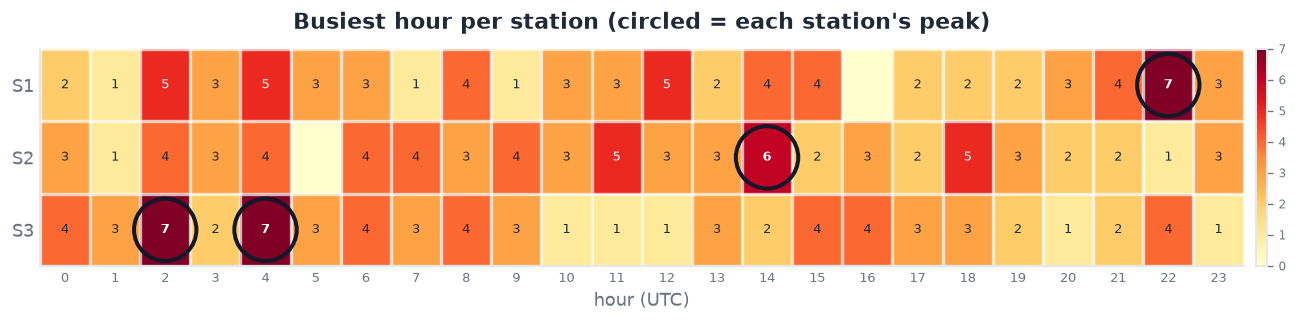

In [6]:
piv = q("SELECT station_id, EXTRACT(hour FROM ts_utc) h, COUNT(DISTINCT track_id) objs "
        "FROM track_points GROUP BY 1,2").pivot(index='station_id', columns='h', values='objs').reindex(columns=range(24)).fillna(0)
fig, a = plt.subplots(figsize=(11, 2.8))
im = a.imshow(piv.values, aspect='auto', cmap='YlOrRd')
a.grid(False)  # the global grid would otherwise cross the cells
a.set_xticks(np.arange(-.5,24,1), minor=True); a.set_yticks(np.arange(-.5,len(piv.index),1), minor=True)
a.grid(which='minor', color='white', linewidth=2)  # clean white cell separators
a.set_xticks(range(24)); a.set_xticklabels(range(24), fontsize=8)
a.set_yticks(range(len(piv.index))); a.set_yticklabels(piv.index, fontsize=11)
a.tick_params(which='both', length=0)
a.set_xlabel('hour (UTC)'); a.set_title("Busiest hour per station (circled = each station's peak)")
V = piv.values; mx = V.max()
for i in range(V.shape[0]):
    rowmax = V[i].max()
    for j in range(V.shape[1]):
        v = int(V[i, j]); peak = (v == rowmax and v > 0)
        if v > 0: a.text(j, i, v, ha='center', va='center', fontsize=7.5,
                         fontweight='bold' if peak else 'normal',
                         color='white' if v > mx*0.6 else INK)
        if peak: a.scatter(j, i, s=1400, facecolors='none', edgecolors='#111827', linewidths=2.4, zorder=5)
cbar = fig.colorbar(im, ax=a, pad=0.01, fraction=0.025); cbar.ax.tick_params(labelsize=7)
plt.tight_layout(); plt.show()

> 📌 **Takeaway** — each station has its own rhythm (S1 runs late ~22:00, S2 midday ~14:00, S3 in the small hours ~02–04:00 UTC), yet hours **02:00–04:00 run warm across all three**. **Caveat:** the sample is one day per month, so each cell holds only a handful of objects — the pattern is *suggestive, not conclusive*; the full dataset (every day of 2025) would confirm it.

## 3 · How fast does each class move? Anything suspicious?
Per-track consecutive-point speed (horizontal haversine), **after** the 150 m/s filter.

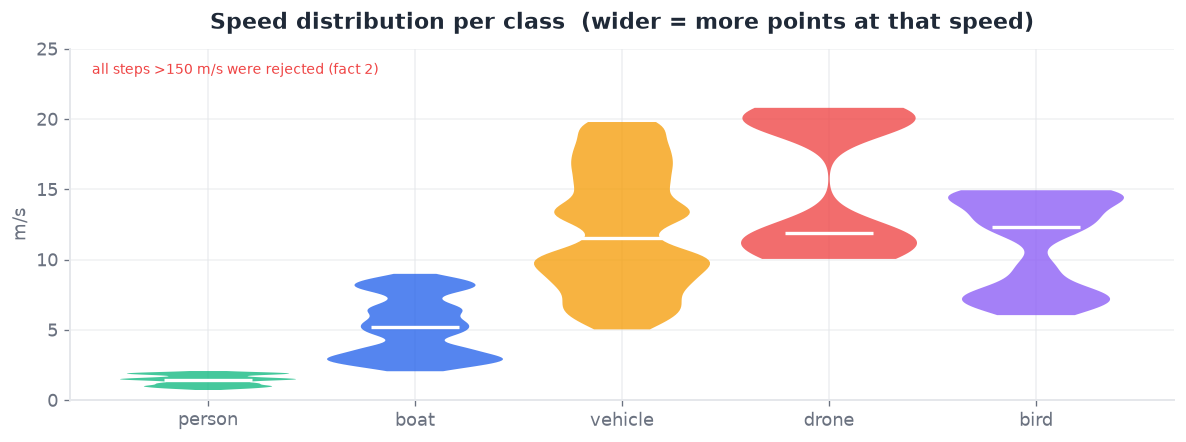

,median,mean,max
class,,,
person,1.46,1.43,2.07
boat,5.19,5.23,8.99
vehicle,11.52,12.08,19.79
drone,11.89,15.30,20.80
bird,12.31,11.10,14.94


In [7]:
tp = q("SELECT station_id, track_id, class, ts_utc, lat, lon FROM track_points ORDER BY 1,2,4")
def hav(a1,o1,a2,o2):
    R=6371000.0; p1,p2=np.radians(a1),np.radians(a2); dp=p2-p1; dl=np.radians(o2-o1)
    x=np.sin(dp/2)**2+np.cos(p1)*np.cos(p2)*np.sin(dl/2)**2; return 2*R*np.arcsin(np.sqrt(x))
g = tp.groupby(['station_id','track_id'])
tp['pa']=g.lat.shift(); tp['po']=g.lon.shift(); tp['pt']=g.ts_utc.shift()
d=hav(tp.pa,tp.po,tp.lat,tp.lon); dt=(tp.ts_utc-tp.pt).dt.total_seconds()
tp['v']=np.where(dt>0, d/dt, np.nan); sp=tp.dropna(subset=['v'])
order=['person','boat','vehicle','drone','bird']
data=[sp[sp['class']==c]['v'].values for c in order]
fig, a = plt.subplots(figsize=(10, 3.8))
parts=a.violinplot(data, showmedians=True, showextrema=False, widths=0.85)
for b,c in zip(parts['bodies'], order): b.set_facecolor(CLASS_COLORS[c]); b.set_edgecolor('none'); b.set_alpha(0.78)
parts['cmedians'].set_color('white'); parts['cmedians'].set_linewidth(2)
a.set_xticks(range(1,len(order)+1)); a.set_xticklabels(order)
a.set_ylim(0, 25); a.set_title('Speed distribution per class  (wider = more points at that speed)')
a.set_ylabel('m/s')
a.annotate('all steps >150 m/s were rejected (fact 2)', (0.02, 0.96), xycoords='axes fraction',
           color='#ef4444', fontsize=8.5, va='top')
for sp_ in ['top','right']: a.spines[sp_].set_visible(False)
a.grid(axis='y', alpha=0.6); a.set_axisbelow(True)
plt.tight_layout(); plt.show()
display(sp.groupby('class')['v'].agg(median='median', mean='mean', max='max').round(2).reindex(order))

**Anything suspicious? Yes — and it's a cleanly separate population.**  
The anomaly isn't in the violin (we already removed it): consecutive points implying impossible speeds. Plotted against the kept data, they sit in their own cloud with a wide empty gap between.

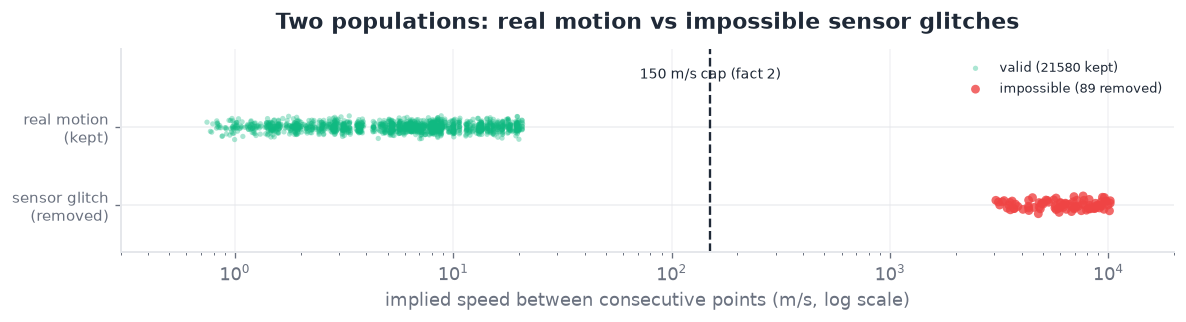

In [8]:
valid = sp['v'].clip(lower=0.01).values
rej = q("SELECT CAST(REPLACE(detail,' m/s','') AS DOUBLE) ms FROM rejects "
        "WHERE source_type='track' AND reason='speed_exceeded'").ms.values
rng = np.random.default_rng(0)
vs = rng.choice(valid, size=min(1500, len(valid)), replace=False)
fig, ax = plt.subplots(figsize=(10, 2.8))
ax.scatter(vs, rng.normal(1,0.05,len(vs)), s=10, color='#10b981', alpha=0.35, edgecolors='none', label=f'valid ({len(valid)} kept)')
ax.scatter(rej, rng.normal(0,0.05,len(rej)), s=28, color='#ef4444', alpha=0.8, edgecolors='none', label=f'impossible ({len(rej)} removed)')
ax.axvline(150, color=INK, ls='--', lw=1.4)
ax.text(150, 1.62, '150 m/s cap (fact 2)', ha='center', fontsize=8.5, color=INK)
ax.set_xscale('log'); ax.set_xlim(0.3, 20000)
ax.set_yticks([0,1]); ax.set_yticklabels(['sensor glitch\n(removed)','real motion\n(kept)'], fontsize=9)
ax.set_ylim(-0.6, 2.0); ax.set_xlabel('implied speed between consecutive points (m/s, log scale)')
ax.set_title('Two populations: real motion vs impossible sensor glitches')
ax.legend(loc='upper right', fontsize=8)
for s in ['top','right']: ax.spines[s].set_visible(False)
ax.grid(axis='x', alpha=0.5); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

> 📌 **Takeaway** — speeds are physically sane (people ~1.5 m/s, boats slow, vehicles/drones/birds faster). **Suspicious?** Yes: 89 points implied **3 000–10 000 m/s** — clearly sensor glitches, a population cleanly separate from real motion (the 150 m/s cap sits in the empty gap between). Minor flag: *bird* and *drone* overlap near ~12 m/s, so speed alone can't tell them apart.

## 4 · Data quality issues
How much data survives, and what we drop. Everything rejected is traceable in the `rejects` table (what / where / why).

**How clean is each stream?** Acceptance rate per data stream:

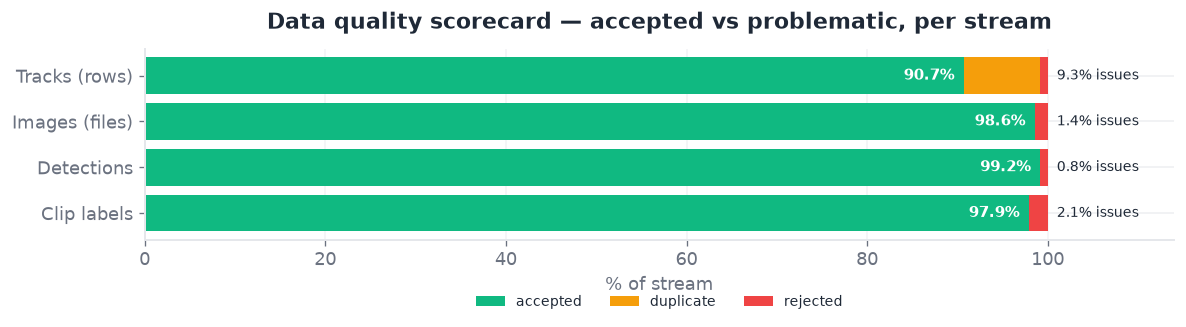

In [9]:
cnt = lambda s: int(con.execute(s).fetchone()[0])
t_read = cnt("SELECT value FROM counters WHERE name='tracks_n_rows_read'")
t_dup  = cnt("SELECT value FROM counters WHERE name='tracks_n_rows_duplicate'")
t_val  = cnt('SELECT COUNT(*) FROM track_points'); t_rej = t_read - t_val - t_dup
im_tot = cnt('SELECT COUNT(*) FROM images'); im_val = cnt('SELECT COUNT(*) FROM images WHERE is_valid')
de_tot = cnt('SELECT COUNT(*) FROM image_detections'); de_val = cnt('SELECT COUNT(*) FROM image_detections WHERE is_valid')
cl_tot = cnt('SELECT COUNT(*) FROM clip_labels'); cl_val = cnt('SELECT COUNT(*) FROM clip_labels WHERE is_valid')
data = [('Tracks (rows)',t_read,t_val,t_dup,t_rej), ('Images (files)',im_tot,im_val,0,im_tot-im_val),
        ('Detections',de_tot,de_val,0,de_tot-de_val), ('Clip labels',cl_tot,cl_val,0,cl_tot-cl_val)]
names=[d[0] for d in data]; yy=np.arange(len(data))
acc=np.array([100*d[2]/d[1] for d in data]); dup=np.array([100*d[3]/d[1] for d in data]); rej=np.array([100*d[4]/d[1] for d in data])
fig,ax=plt.subplots(figsize=(10,3.0))
ax.barh(yy,acc,color='#10b981',label='accepted'); ax.barh(yy,dup,left=acc,color='#f59e0b',label='duplicate'); ax.barh(yy,rej,left=acc+dup,color='#ef4444',label='rejected')
for i in range(len(data)):
    ax.text(acc[i]-1,i,f'{acc[i]:.1f}%',va='center',ha='right',color='white',fontsize=9,fontweight='bold')
    prob=dup[i]+rej[i]
    if prob>0.5: ax.text(101,i,f'{prob:.1f}% issues',va='center',ha='left',color=INK,fontsize=8.5)
ax.set_yticks(yy); ax.set_yticklabels(names); ax.set_xlim(0,114); ax.set_xlabel('% of stream')
ax.set_title('Data quality scorecard — accepted vs problematic, per stream')
ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5,-0.22), fontsize=8.5, frameon=False)
ax.invert_yaxis()
for s in ['top','right']: ax.spines[s].set_visible(False)
ax.grid(axis='x', alpha=0.5); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

**What exactly was dropped?** Rejected records by issue:

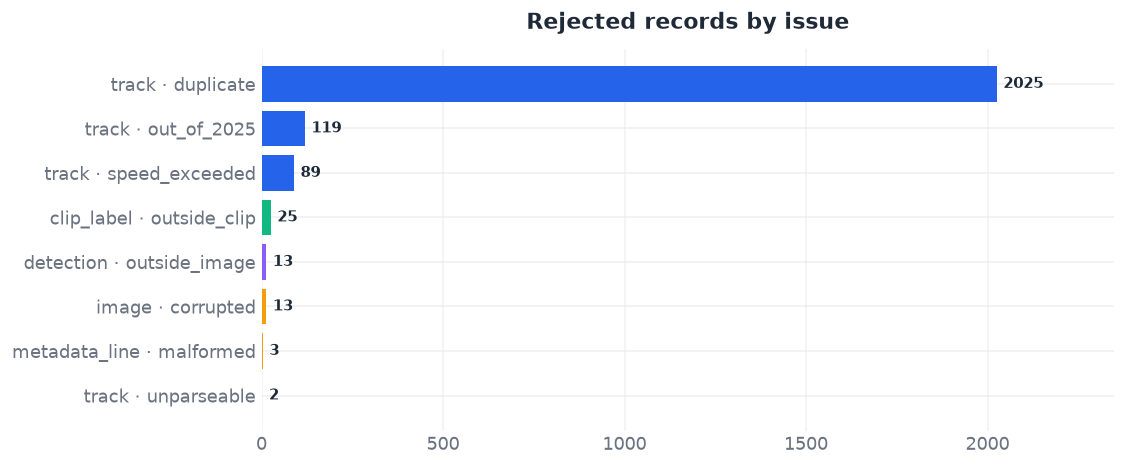

In [10]:
rj = q("SELECT source_type, reason, COUNT(*) n FROM rejects GROUP BY 1,2 ORDER BY 3")
rj['label'] = rj['source_type'] + ' · ' + rj['reason']
src_color = {'track':'#2563eb','image':'#f59e0b','metadata_line':'#f59e0b',
             'detection':'#8b5cf6','clip_label':'#10b981','clip':'#10b981'}
fig, a = plt.subplots(figsize=(9.5, 4))
bars=a.barh(rj['label'], rj['n'], color=[src_color.get(s,'#9ca3af') for s in rj['source_type']], zorder=3)
a.bar_label(bars, padding=4, color=INK, fontsize=9, fontweight='bold')
a.set_title('Rejected records by issue'); a.margins(x=0.16); despine(a)
plt.tight_layout(); plt.show()

| Issue | What the pipeline does |
|---|---|
| `track · duplicate` | same (station, track, timestamp) again, incl. `_resend` files → counted once |
| `track · out_of_2025` | timestamp outside 2025 **after UTC conversion** → dropped (fact 1) |
| `track · speed_exceeded` | step implies >150 m/s → dropped (fact 2) |
| `track · unparseable` | truncated row / missing id/lat/lon → dropped |
| `image · corrupted` | header-valid but truncated, or not an image (`.DS_Store`) → not copied |
| `metadata_line · malformed` | unreadable JSON line → skipped, file continues |
| `detection · outside_image` | box entirely outside the frame → not counted |
| `clip_label · outside_clip` | label frame/time beyond the clip length → not counted |

> 📌 **Takeaway** — the data is largely usable: **>97% of images, detections and clip labels are accepted**; tracks sit at 90.7%, and that gap is almost entirely **duplicate rows from `_resend` files** (8.4%), not real errors. Every issue is counted and traceable in `rejects`. The biggest trap was a firmware shipping a *seconds* header but *millisecond* values (→ the year 57297); magnitude-based unit detection recovered 1 338 points.

## 5 · With one more day
- **Parallelise image validation** (I/O-bound, ~90% of the 1M files) — the main remaining bottleneck (slow, never crashes).
- **Extend deduplication beyond tracks** — only tracks are deduped today (fact 6 is track-specific; images/detections/clips were verified duplicate-free in the sample). If the full dataset resends detection or clip files, the same `ROW_NUMBER` dedup should cover them.
- **Add data tests** (schema, invariant, range checks) so a new firmware surprise fails loudly instead of quietly skewing a metric.
- **Reconcile `track_id` across firmwares** and flag tracks whose class is inconsistent.
- **Unified cross-sensor activity view** — store detection timestamps too, so *when is the harbour busy?* can be answered across all three streams, not just tracks.